# Linear Regression from Scratch with Evaluation Metrics and Visualizations

In [2]:
class MeraLR:
    
    def __init__(self):
        self.m = None
        self.b = None
        
    def fit(self,X_train,y_train):
        
        num = 0
        den = 0
        
        for i in range(X_train.shape[0]):
            
            num = num + ((X_train[i] - X_train.mean())*(y_train[i] - y_train.mean()))
            den = den + ((X_train[i] - X_train.mean())*(X_train[i] - X_train.mean()))
        
        self.m = num/den
        self.b = y_train.mean() - (self.m * X_train.mean())
        print(self.m)
        print(self.b)       
    
    def predict(self,X_test):
        
        print(X_test)
        
        return self.m * X_test + self.b

## 1. Import Libraries

In [3]:
import numpy as np
import pandas as pd

## 2. Load Dataset

In [9]:
df = pd.read_csv(r'placement.csv')

In [10]:
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


## 3. Prepare Features and Target

In [11]:
X = df.iloc[:,0].values
y = df.iloc[:,1].values

## 4. Train-Test Split

In [12]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

## 5. Train the Model

In [13]:
lr = MeraLR()

In [14]:
lr.fit(X_train,y_train)

0.5579519734250721
-0.8961119222429152


## 6. Evaluate the Model

In [15]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predictions on test set
y_pred = np.array([lr.predict(x) for x in X_test])

# Metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

n = len(y_test)
p = 1  # number of predictors

adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
rse = np.sqrt(np.sum((y_test - y_pred) ** 2) / (n - p - 1))

# Display metrics
print("Regression Evaluation Metrics")
print(f"MAE         : {mae:.4f}")
print(f"MSE         : {mse:.4f}")
print(f"RMSE        : {rmse:.4f}")
print(f"R²          : {r2:.4f}")
print(f"Adjusted R² : {adj_r2:.4f}")
print(f"MAPE (%)    : {mape:.2f}")
print(f"RSE         : {rse:.4f}")


8.58
7.15
5.88
6.22
4.57
4.79
5.32
6.86
8.35
6.87
8.94
7.9
6.93
5.91
7.32
7.82
5.09
7.42
6.94
7.73
6.19
7.28
6.73
7.2
8.21
6.75
7.87
7.6
8.63
5.12
8.15
7.36
8.31
6.6
6.59
7.47
7.93
6.29
6.37
6.47
Regression Evaluation Metrics
MAE         : 0.2885
MSE         : 0.1213
RMSE        : 0.3483
R²          : 0.7807
Adjusted R² : 0.7750
MAPE (%)    : 10.62
RSE         : 0.3573


## 7. Visualizations

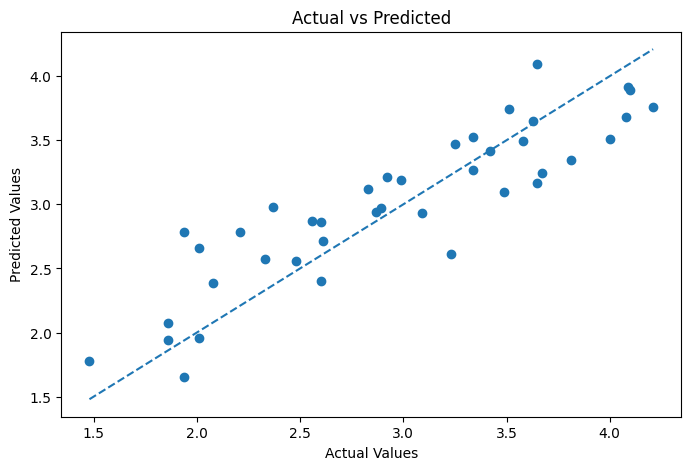

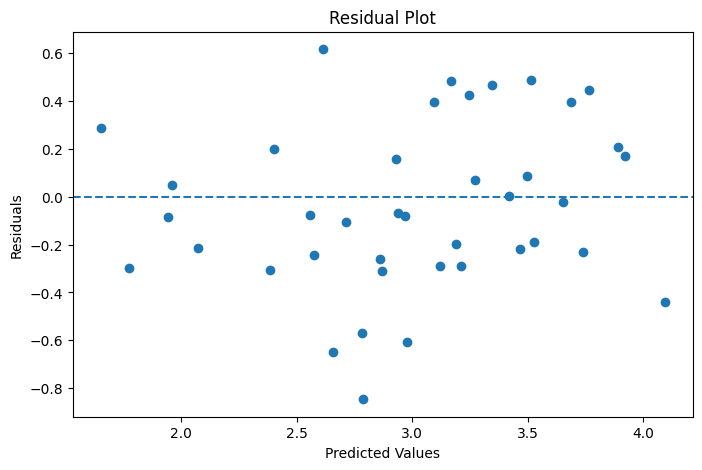

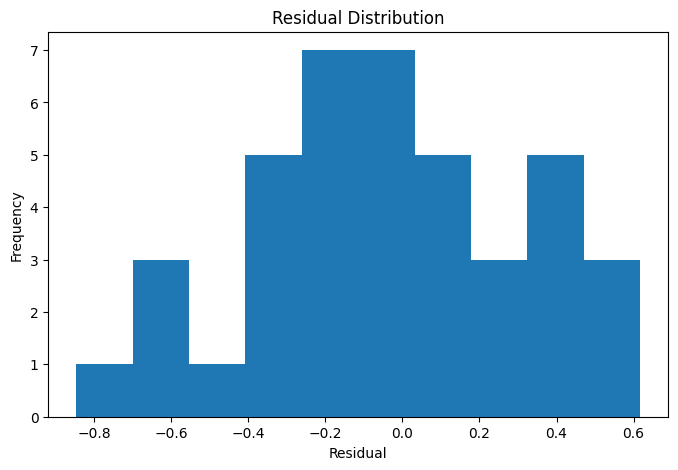

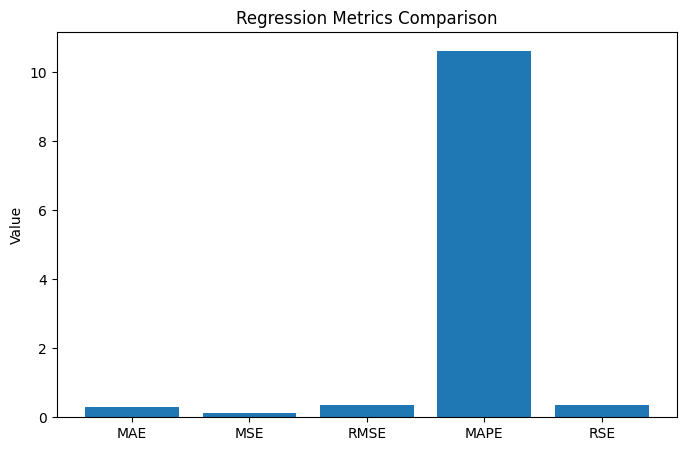

In [16]:

import matplotlib.pyplot as plt

# Residuals
residuals = y_test - y_pred

# 1. Actual vs Predicted
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred)
plt.plot(
    [min(y_test), max(y_test)],
    [min(y_test), max(y_test)],
    linestyle='--'
)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted")
plt.show()

# 2. Residual Plot
plt.figure(figsize=(8,5))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, linestyle='--')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

# 3. Residual Distribution
plt.figure(figsize=(8,5))
plt.hist(residuals, bins=10)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Residual Distribution")
plt.show()

# 4. Metrics Comparison
metric_names = ["MAE", "MSE", "RMSE", "MAPE", "RSE"]
metric_values = [mae, mse, rmse, mape, rse]

plt.figure(figsize=(8,5))
plt.bar(metric_names, metric_values)
plt.ylabel("Value")
plt.title("Regression Metrics Comparison")
plt.show()
